# Monte Carlo con cópulas: gaussiana y t de Student, con sus errores de Monte Carlo

- **Nivel:** 2, El método en la práctica
- **Requisitos previos:** los cuadernos 01 y 02 de este tema (la distribución de la cartera grande y la correlación ajustada)
- **Tiempo de lectura:** unos 45 minutos

## Objetivos

Al terminar este cuaderno puedes:

- describir la cartera ilustrativa del caso y construirla con el motor a partir de sus grupos de nombres idénticos;
- simular la pérdida de una cartera finita bajo una cópula gaussiana de un factor, una cópula gaussiana de dos sectores y una cópula t de Student, y leer VaR, déficit esperado y capital de cada muestra;
- decir qué es la dependencia de cola, y comprobar con dos nombres que la cópula t pone varias veces más probabilidad en un incumplimiento conjunto que la cópula gaussiana con la misma correlación;
- leer un error estándar de Monte Carlo, ver cómo se reduce con el número de escenarios, y decir cuándo un error de medias por lotes en la cola lejana no es confiable;
- ver cómo el VaR de Monte Carlo de una cartera de N nombres converge al cuantil de la cartera grande cuando N crece, y leer la prueba de convergencia del motor.

## Preparación

Instala una vez el entorno fijado, en un entorno virtual, con el comando de siempre:

```bash
pip install -r notebooks/requirements.txt
```

o solo los paquetes que usa este cuaderno, con las mismas versiones exactas:

```bash
pip install riskvalidation==0.9.0 numpy==2.4.6 scipy==1.18.1 matplotlib==3.11.2
```

`scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` en Windows) construye `.venv-notebooks` por ti. La celda siguiente importa los paquetes e imprime sus versiones.

In [1]:
# Importar las herramientas e imprimir las versiones con que corren, para compararlas con notebooks/requirements.txt
import importlib.metadata as md
import json
import math
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from scipy import stats

# El cuaderno está tres carpetas por debajo de la raíz del repositorio
ROOT = Path("../../..").resolve()

for name in ("riskvalidation", "numpy", "scipy", "matplotlib",):
    print(name, md.version(name))

# Mostrar un valor lógico o una etiqueta del motor en español, también dentro de listas y diccionarios
ETIQUETAS = {
    "green": "verde", "amber": "ámbar", "red": "rojo", "not_evaluated": "no evaluada", "illustrative": "ilustrativa",
    "synthetic-calibrated": "sintética calibrada", "withheld-derived-only": "retenidas, solo derivados", "included": "incluidas",
    "fitted": "ajustado", "challenger-not-run": "retador no ejecutado",
}


def si_no(valor):
    if isinstance(valor, dict):
        return {ETIQUETAS.get(k, k): si_no(v) for k, v in valor.items()}
    if getattr(valor, 'ndim', 0) > 0:
        return si_no(valor.tolist())
    if isinstance(valor, (list, tuple)):
        return [si_no(v) for v in valor]
    if isinstance(valor, str):
        return ETIQUETAS.get(valor, valor)
    return "sí" if valor else "no"

riskvalidation 0.8.1
numpy 2.4.6
scipy 1.18.1
matplotlib 3.11.2


## Datos

Los datos son el archivo comercial e industrial del caso C10, `data/derived/C10/commercial-industrial.json` (propietario: este repositorio; las tasas de pérdida detrás de su ajuste vienen de la tabla `chgallsa` de la Reserva Federal, https://www.federalreserve.gov/releases/chargeoff/chgallsa.htm, dominio público, clase de licencia `mirror-allowed`). Tres bloques importan aquí:

- `outputs.portfolio`: la **cartera ilustrativa**, construida para el caso con la PD y la correlación ajustadas y nunca la de un banco: tres grupos de nombres idénticos (20 grandes, 100 medianos y 1.000 pequeños), 100 millones de USD de exposición en total, una LGD de 45%, y una PD por grupo escalada para que la PD ponderada por exposición sea la ajustada. Clase de licencia `illustrative`;
- `outputs.fit`: la PD y la correlación ajustadas del cuaderno 02;
- `outputs.rungs`: la escalera versionada, con las medidas de cada peldaño y el número de escenarios y la semilla de su Monte Carlo. Aquí usamos los peldaños gaussiano, sectorial y t de Student, y `tests` para la fila de convergencia versionada.

La celda siguiente carga el archivo, imprime los grupos y la concentración de la cartera, e imprime cómo se simularon los peldaños versionados.

In [2]:
# Cargar el artefacto, imprimir los grupos de la cartera ilustrativa y cómo se simularon los peldaños versionados
doc = json.loads((ROOT / "data" / "derived" / "C10" / "commercial-industrial.json").read_text(encoding="utf-8"))
out = doc["outputs"]
book = out["portfolio"]
ml = out["fit"]["maximum_likelihood"]
pd_hat, rho_hat = ml["pd"]["estimate"], ml["rho"]["estimate"]
rungs = {r["id"]: r for r in out["rungs"]}

print("etiqueta de la cartera:", si_no(book["label"]), "| nombres:", book["n_names"], "| exposición total:", f"{book['total_ead']:,.0f}", book["currency"])
for g in book["groups"]:
    print(f"{g['id']:9s} {g['n_names']:5d} nombres x {g['ead_each']:>11,.0f} | PD {g['pd']:.5f} | LGD {g['lgd']} | carga {g['loading']:.4f} | sector {g['sector']}")
print("HHI:", book["hhi"], "| nombres efectivos:", round(book["effective_names"], 1), "| participación del mayor nombre:", book["largest_share"])

print("calculado con riskvalidation", doc["provenance"]["riskvalidation_version"])
for rid in ("c2-gaussian-1f", "c2-gaussian-mf", "c3-student-t"):
    print(rid, rungs[rid]["simulation"], [(p["name"], p["value"]) for p in rungs[rid]["parameters"]])

etiqueta de la cartera: ilustrativa | nombres: 1120 | exposición total: 100,000,000 USD
g-large      20 nombres x   2,000,000 | PD 0.00506 | LGD 0.45 | carga 0.2523 | sector core
g-mid       100 nombres x     400,000 | PD 0.01012 | LGD 0.45 | carga 0.2523 | sector core
g-small    1000 nombres x      20,000 | PD 0.01517 | LGD 0.45 | carga 0.2523 | sector periphery
HHI: 0.00964 | nombres efectivos: 103.7 | participación del mayor nombre: 0.02
calculado con riskvalidation 0.7.0
c2-gaussian-1f {'n_scenarios': 1000000, 'seed': 4001, 'chunk_size': 16741} [('rho', 0.0636765484), ('lgd', 0.45)]
c2-gaussian-mf {'n_scenarios': 1000000, 'seed': 4002, 'chunk_size': 16741} [('n_factors', 2.0), ('factor_correlation', 0.5), ('rho', 0.0636765484), ('lgd', 0.45)]
c3-student-t {'n_scenarios': 1000000, 'seed': 4003, 'chunk_size': 16741} [('nu', 5.0), ('rho', 0.0636765484), ('lgd', 0.45)]


## Método

### Paso 1: la cópula gaussiana y la pérdida de una cartera finita

Las fórmulas de cartera grande del cuaderno 01 necesitan infinitos préstamos. Una cartera real tiene un número finito de nombres con exposiciones y PD distintas, así que su pérdida es aleatoria incluso dada la economía. El modelo de **cópula gaussiana** conserva el retorno latente de activos del modelo de un factor pero deja que cada nombre tenga su propia carga $\beta_i$ sobre un vector de factores sistemáticos $Z\sim N(0,\Sigma)$ (Li, 2000, https://doi.org/10.3905/jfi.2000.319253):

$$A_i = \beta_i^\top Z + \sqrt{1-\beta_i^\top\beta_i}\,\varepsilon_i, \qquad D_i = \mathbf 1\{A_i < \Phi^{-1}(\mathrm{PD}_i)\}, \qquad L = \sum_i \mathrm{EAD}_i\,\mathrm{LGD}_i\,D_i$$

con un factor cuando todas las cargas son $\sqrt\rho$. La pérdida no tiene forma cerrada, así que el motor la simula: `portfolio_from_groups` expande los grupos en nombres, y `simulate_gaussian` sortea los escenarios con un generador con semilla, así que una corrida es reproducible para la misma semilla, número de escenarios y tamaño de bloque. A partir de la muestra, `measures_from_sample` devuelve la pérdida esperada que da la cartera, el VaR como cuantil muestral, el déficit esperado con los pesos de Acerbi y Tasche (https://doi.org/10.1016/S0378-4266(02)00283-2), el capital $\mathrm{VaR}-\mathrm{EL}$ y los errores estándar por medias de lotes. Aquí usamos 100.000 escenarios, una décima parte de la corrida versionada, y la semilla y el tamaño de bloque del pipeline. La celda siguiente construye la cartera y corre la cópula de un factor.

In [3]:
# Construir la cartera y simular 100,000 escenarios de la cópula gaussiana de un factor
from riskvalidation.portfolio import copula
from riskvalidation.portfolio import portfolio as pf

groups = book["groups"]
one = pf.portfolio_from_groups(groups, book["currency"], book["lgd_gamma"], one_factor=True)
el = pf.expected_loss(one)
print("nombres:", one.ead.size, "| factores:", one.loadings.shape[1], "| EL:", f"{el:,.0f}", "| EL versionada:", f"{rungs['c2-gaussian-1f']['measures'][0]['el']:,.0f}")

N_SCENARIOS, CHUNK = 100_000, rungs["c2-gaussian-1f"]["simulation"]["chunk_size"]
sample_1f = copula.simulate_gaussian(one, N_SCENARIOS, rungs["c2-gaussian-1f"]["simulation"]["seed"], CHUNK)
measures_1f = pf.measures_from_sample(sample_1f.losses, (0.99, 0.999), el)

print(f"{'q':>6s} {'VaR':>12s} {'error est.':>10s} {'ES':>12s} {'capital':>12s} | {'VaR versionado (1M)':>26s} {'error est.':>10s} {'z':>6s}")
for m, c in zip(measures_1f, rungs["c2-gaussian-1f"]["measures"]):
    z = (m.var - c["var"]) / math.hypot(m.var_se, c["var_se"])
    print(f"{m.level:6.3f} {m.var:12,.0f} {m.var_se:10,.0f} {m.es:12,.0f} {m.ec:12,.0f} | {c['var']:26,.0f} {c['var_se']:10,.0f} {z:6.2f}")

nombres: 1120 | factores: 1 | EL: 409,721 | EL versionada: 409,721
     q          VaR error est.           ES      capital |        VaR versionado (1M) error est.      z
 0.990    2,088,000     18,433    2,535,057    1,678,279 |                  2,097,000      4,792  -0.47
 0.999    3,087,000     54,340    3,609,180    2,677,279 |                  3,177,000     15,163  -1.60


Una muestra de 100.000 escenarios y una de 1.000.000 difieren solo por ruido de Monte Carlo, así que la diferencia dividida por el error estándar combinado, la última columna, debe ser pequeña: dentro de unos dos. La corrida versionada es la más precisa de las dos y es la referencia. A continuación, una segunda fuente de dependencia: los nombres de distintos sectores.

In [4]:
# Construir la cartera de dos sectores (núcleo y periferia) y simularla con la correlación de factores versionada
factor_rho = next(p["value"] for p in rungs["c2-gaussian-mf"]["parameters"] if p["name"] == "factor_correlation")
factor_corr = np.array([[1.0, factor_rho], [factor_rho, 1.0]])
multi = pf.portfolio_from_groups(groups, book["currency"], book["lgd_gamma"], factor_corr=factor_corr, one_factor=False)
print("factores:", multi.loadings.shape[1], "| correlación entre los dos factores sectoriales:", factor_rho)

sample_mf = copula.simulate_gaussian(multi, N_SCENARIOS, rungs["c2-gaussian-mf"]["simulation"]["seed"], CHUNK)
measures_mf = pf.measures_from_sample(sample_mf.losses, (0.99, 0.999), el)
for m1, mm, c in zip(measures_1f, measures_mf, rungs["c2-gaussian-mf"]["measures"]):
    print(f"q = {m1.level}: VaR un factor {m1.var:,.0f} | VaR dos sectores {mm.var:,.0f} | dos sectores versionado (1M) {c['var']:,.0f}")

factores: 2 | correlación entre los dos factores sectoriales: 0.5
q = 0.99: VaR un factor 2,088,000 | VaR dos sectores 2,025,000 | dos sectores versionado (1M) 2,007,000
q = 0.999: VaR un factor 3,087,000 | VaR dos sectores 2,988,000 | dos sectores versionado (1M) 3,033,000


Con dos factores sectoriales correlacionados en 0,5 en lugar de un factor compartido por todos los nombres, la periferia y el núcleo ya no caen juntos cada vez, y la cola de la pérdida es más delgada. La cópula de un factor es la más conservadora de las dos en esta cartera.

### Paso 2: la cópula t de Student y la dependencia de cola

La cópula gaussiana tiene una debilidad conocida: por alta que sea la correlación, los eventos extremos de dos nombres se vuelven independientes lo bastante lejos en la cola. La **cópula t de Student** divide el retorno de activos por una escala aleatoria común, $A_i=\sqrt{W}\,(\beta_i^\top Z+\sqrt{1-\beta_i^\top\beta_i}\,\varepsilon_i)$ con $W=\nu/\chi^2_\nu$, y un nombre cae en incumplimiento cuando $A_i < t_\nu^{-1}(\mathrm{PD}_i)$ (Frey y McNeil, 2003, https://doi.org/10.21314/jor.2003.089; Demarta y McNeil, 2005, https://doi.org/10.1111/j.1751-5823.2005.tb00254.x). El mismo $W$ multiplica a todos los nombres, así que un $W$ pequeño los mueve juntos: esto es la **dependencia de cola**, y aumenta la probabilidad de un incumplimiento conjunto con la misma correlación de activos. La PD marginal de cada nombre no cambia. `simulate_student_t` del motor recibe los grados de libertad $\nu>2$; el peldaño versionado usa $\nu=5$. La celda siguiente la simula y pone las tres cópulas lado a lado.

In [5]:
# Simular la cópula t de Student con los grados de libertad versionados y comparar las tres cópulas
nu = next(p["value"] for p in rungs["c3-student-t"]["parameters"] if p["name"] == "nu")
sample_t = copula.simulate_student_t(one, nu, N_SCENARIOS, rungs["c3-student-t"]["simulation"]["seed"], CHUNK)
measures_t = pf.measures_from_sample(sample_t.losses, (0.99, 0.999), el)
print("nu =", nu)

print(f"{'q':>6s} {'Gaussiana 1F':>16s} {'Gaussiana 2 sect.':>20s} {'Student t':>14s} {'t / gaussiana':>14s}")
for a, b, c in zip(measures_1f, measures_mf, measures_t):
    print(f"{a.level:6.3f} {a.var:16,.0f} {b.var:20,.0f} {c.var:14,.0f} {c.var / a.var:14.2f}")
committed_t = rungs["c3-student-t"]["measures"][-1]["var"] / rungs["c2-gaussian-1f"]["measures"][-1]["var"]
print("razón versionada al 99.9% (1M de escenarios):", round(committed_t, 3), "| impact.var_999_student_t_over_gaussian:", round(doc["impact"]["var_999_student_t_over_gaussian"]["value"], 3))

nu = 5.0
     q     Gaussiana 1F    Gaussiana 2 sect.      Student t  t / gaussiana
 0.990        2,088,000            2,025,000      6,264,000           3.00
 0.999        3,087,000            2,988,000     13,815,000           4.48
razón versionada al 99.9% (1M de escenarios): 4.122 | impact.var_999_student_t_over_gaussian: 4.122


La dependencia de cola se puede comprobar en la cartera más pequeña posible, dos nombres. Para dos nombres con la PD y la correlación ajustadas, la simulación del motor da la probabilidad de que ambos caigan en incumplimiento; las funciones de distribución normal bivariada y t bivariada de SciPy dan la misma probabilidad en forma cerrada, desde la definición de las cópulas. La independencia daría $\mathrm{PD}^2$. La celda siguiente usa 4 millones de escenarios de dos nombres, lo que toma menos de un segundo.

In [6]:
# Probabilidad de que dos nombres caigan juntos en incumplimiento: simulación del motor frente a las distribuciones bivariadas de SciPy
pair = pf.portfolio_from_groups(
    [{"id": "pair", "n_names": 2, "ead_each": 1_000_000.0, "pd": pd_hat, "lgd": 0.45, "loading": math.sqrt(rho_hat), "sector": "core"}],
    "USD", 0.25, one_factor=True)
scenarios = 4_000_000
one_name_loss = 1_000_000.0 * 0.45
pair_gauss = copula.simulate_gaussian(pair, scenarios, 11, 100_000)
pair_t = copula.simulate_student_t(pair, nu, scenarios, 12, 100_000)
both_gauss = float(np.mean(pair_gauss.losses > 1.5 * one_name_loss))
both_t = float(np.mean(pair_t.losses > 1.5 * one_name_loss))

corr = np.array([[1.0, rho_hat], [rho_hat, 1.0]])
# La t bivariada de SciPy integra con una regla aleatoria: una semilla fija y un millón de puntos hacen reproducible el valor
exact_gauss = float(stats.multivariate_normal.cdf([stats.norm.ppf(pd_hat)] * 2, cov=corr, maxpts=1_000_000))
exact_t = float(stats.multivariate_t.cdf([stats.t.ppf(pd_hat, nu)] * 2, shape=corr, df=nu, maxpts=1_000_000, random_state=0))
print("PD:", round(pd_hat, 5), "| nombres independientes: PD al cuadrado:", f"{pd_hat ** 2:.3e}")
print(f"Gaussiana: motor {both_gauss:.3e} | SciPy {exact_gauss:.3e}")
print(f"Student t: motor {both_t:.3e} | SciPy {exact_t:.3e}")
print("incumplimiento conjunto, gaussiana sobre independiente (SciPy):", round(exact_gauss / pd_hat ** 2, 2))
print("incumplimiento conjunto, t sobre gaussiana (SciPy):", round(exact_t / exact_gauss, 2))

PD: 0.0091 | nombres independientes: PD al cuadrado: 8.290e-05
Gaussiana: motor 1.385e-04 | SciPy 1.287e-04
Student t: motor 8.245e-04 | SciPy 8.049e-04
incumplimiento conjunto, gaussiana sobre independiente (SciPy): 1.55
incumplimiento conjunto, t sobre gaussiana (SciPy): 6.26


La imagen compara las colas. La celda siguiente dibuja la probabilidad de que la pérdida supere cada nivel, en eje logarítmico, para las tres muestras, con los niveles de VaR marcados. Donde las curvas se separan es donde los modelos discrepan sobre el capital.

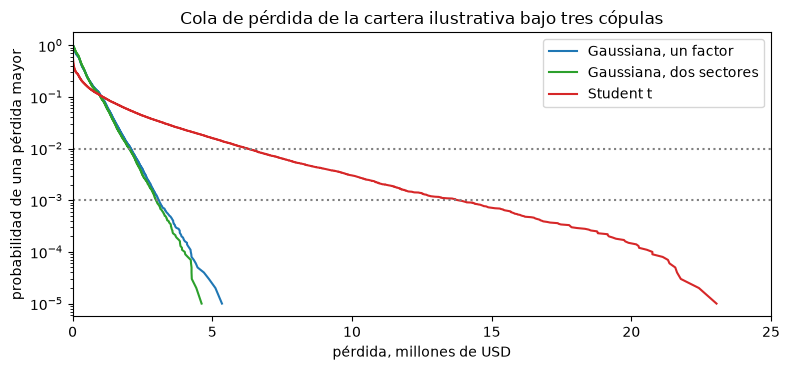

In [7]:
# Dibujar la probabilidad de superar cada nivel de pérdida para las tres muestras en eje logarítmico
fig, ax = plt.subplots(figsize=(8, 3.8))
for sample, label, color in ((sample_1f, "Gaussiana, un factor", "tab:blue"), (sample_mf, "Gaussiana, dos sectores", "tab:green"), (sample_t, "Student t", "tab:red")):
    ordered = np.sort(sample.losses)
    exceed = 1.0 - (np.arange(1, ordered.size + 1) / ordered.size)
    keep = exceed > 0
    ax.plot(ordered[keep] / 1e6, exceed[keep], label=label, color=color)
for q in (0.99, 0.999):
    ax.axhline(1 - q, color="gray", linestyle=":")
ax.set_yscale("log")
ax.set_xlim(0, 25)
ax.set_xlabel("pérdida, millones de USD")
ax.set_ylabel("probabilidad de una pérdida mayor")
ax.set_title("Cola de pérdida de la cartera ilustrativa bajo tres cópulas")
ax.legend()
fig.tight_layout()
plt.show()

### Paso 3: el error estándar de Monte Carlo

Un VaR de Monte Carlo es una estimación, y un validador necesita saber cuán precisa es. `mc_standard_errors` del motor divide la muestra en lotes consecutivos (20 por defecto), calcula VaR y ES en cada uno, e informa la desviación estándar de las estimaciones de los lotes sobre $\sqrt{20}$; este estimador es una elección del contrato del motor, la investigación no nombra ninguno. El error debe reducirse como $1/\sqrt S$ con el número de escenarios $S$. La celda siguiente toma los primeros 10.000, 25.000, 50.000 y 100.000 escenarios de la muestra gaussiana e imprime los errores estándar al 99% y al 99,9%.

In [8]:
# Errores estándar de VaR y ES al 99% y al 99.9% para números crecientes de escenarios
from riskvalidation.portfolio.copula import mc_standard_errors

print(f"{'escenarios':>10s} {'EE del VaR 99%':>16s} {'EE del ES 99%':>16s} {'EE del VaR 99.9%':>18s} {'pérdidas por lote':>20s}")
se_99, se_999 = {}, {}
for n in (10_000, 25_000, 50_000, 100_000):
    v99, e99 = mc_standard_errors(sample_1f.losses[:n], 0.99, 20)
    v999, _ = mc_standard_errors(sample_1f.losses[:n], 0.999, 20)
    se_99[n], se_999[n] = v99, v999
    print(f"{n:10,d} {v99:16,.0f} {e99:16,.0f} {v999:18,.0f} {n // 20:20,d}")
print("razón de los errores del VaR 99%, 10,000 a 100,000 escenarios:", round(se_99[10_000] / se_99[100_000], 2), "| sqrt(10) =", round(math.sqrt(10), 2))
print("razón de los errores del VaR 99.9%, 10,000 a 100,000 escenarios:", round(se_999[10_000] / se_999[100_000], 2))
print("escenarios de cola en un lote de 5,000 al 99.9%:", round(5_000 * (1 - 0.999), 1))

escenarios   EE del VaR 99%    EE del ES 99%   EE del VaR 99.9%    pérdidas por lote
    10,000           67,701           62,462             97,473                  500
    25,000           40,518           50,757             79,648                1,250
    50,000           24,976           33,882             65,394                2,500
   100,000           18,433           24,792             54,340                5,000
razón de los errores del VaR 99%, 10,000 a 100,000 escenarios: 3.67 | sqrt(10) = 3.16
razón de los errores del VaR 99.9%, 10,000 a 100,000 escenarios: 1.79
escenarios de cola en un lote de 5,000 al 99.9%: 5.0


### Paso 4: la convergencia al límite de la cartera grande, y la prueba del motor

Una cartera finita queda sobre el cuantil de la cartera grande por un efecto de granularidad que se desvanece cuando crece el número de nombres. Para una cartera de $N$ nombres idénticos con la PD y la correlación ajustadas, el VaR de Monte Carlo debe converger al `lhp_quantile` cerrado del cuaderno 01. `mc_convergence` del motor prueba la estimación contra un ancla analítica: el estadístico es $(\text{estimación}-\text{ancla})/\mathrm{ee}$ y su valor p es el valor p normal de dos colas; es una puerta interna de Contraste, verde desde 0,05 y roja bajo 0,01, y solo tiene sentido para una cartera cercana al límite. La celda siguiente simula 50.000 escenarios para cinco tamaños de cartera, de 20 a 5.000 nombres, sobre los mismos 100 millones de USD de exposición, y prueba cada uno contra el ancla.

In [9]:
# Simular carteras de 20 a 5,000 nombres idénticos y probar cada VaR de Monte Carlo contra el cuantil de la cartera grande
from riskvalidation.validation.portfolio import mc_convergence

anchor = pf.lhp_measures(book["total_ead"], book["lgd_mean"], pd_hat, rho_hat, (0.999,))[0].var
print("VaR de la cartera grande al 99.9%:", f"{anchor:,.0f}")
print(f"{'nombres':>7s} {'VaR MC':>12s} {'error est.':>10s} {'VaR / ancla':>13s} {'p':>9s} luz")
ratios = {}
for n_names in (20, 100, 500, 2000, 5000):
    identical = pf.portfolio_from_groups(
        [{"id": "g", "n_names": n_names, "ead_each": book["total_ead"] / n_names, "pd": pd_hat, "lgd": book["lgd_mean"], "loading": math.sqrt(rho_hat), "sector": "core"}],
        book["currency"], book["lgd_gamma"], one_factor=True)
    chunk = max(1000, min(100_000, 150_000_000 // (8 * n_names)))
    run = copula.simulate_gaussian(identical, 50_000, 4005, chunk)
    m = pf.measures_from_sample(run.losses, (0.999,), pf.expected_loss(identical))[0]
    verdict = mc_convergence(m.var, m.var_se, anchor, "var", model_id="identical-names", segment=f"{n_names}-names")
    ratios[n_names] = m.var / anchor
    print(f"{n_names:7d} {m.var:12,.0f} {m.var_se:10,.0f} {m.var / anchor:13.3f} {verdict.p_value:9.2e} {si_no(verdict.light.value)}")

committed_row = next(t for t in doc["tests"] if t["test_id"] == "portfolio.mc_convergence")
print("fila versionada:", committed_row["segment"], "| p-value", round(committed_row["p_value"], 4), "|", si_no(committed_row["light"]), "| estimate", f"{committed_row['extras']['estimate']:,.0f}", "| anchor", f"{committed_row['extras']['anchor']:,.0f}")

VaR de la cartera grande al 99.9%: 2,298,833
nombres       VaR MC error est.   VaR / ancla         p luz
     20    6,750,000    112,500         2.936  0.00e+00 rojo
    100    3,150,000     94,618         1.370  2.35e-19 rojo
    500    2,520,000     40,828         1.096  6.06e-08 rojo
   2000    2,340,000     56,589         1.018  4.67e-01 verde
   5000    2,286,000     64,970         0.994  8.43e-01 verde
fila versionada: lhp-like-99.9 | p-value 0.5866 | verde | estimate 2,286,000 | anchor 2,298,834


## Resultados

- **La cartera finita necesita una simulación, y la simulación concuerda con la referencia dentro de su ruido.** En la cartera ilustrativa de 1.120 nombres, la cópula gaussiana de un factor con 100.000 escenarios da un VaR al 99% de 2.088.000 USD y un VaR al 99,9% de 3.087.000 USD, con capital de 1.678.279 y 2.677.279 USD. La corrida versionada de un millón de escenarios da 2.097.000 y 3.177.000 USD; las diferencias son -0,47 y -1,60 errores estándar combinados. Ambos quedan sobre el VaR de la cartera grande de 2.298.833 USD al 99,9% del cuaderno 01, porque la cartera tiene 104 nombres efectivos, no infinitos.
- **Dos sectores bajan la cola, un factor es la elección conservadora.** Con dos factores sectoriales correlacionados en 0,5, el VaR al 99,9% es 2.988.000 USD frente a 3.087.000 USD con un factor (las corridas versionadas: 3.033.000 y 3.177.000). Las cargas son las mismas; lo que cambia es que el núcleo y la periferia ya no caen juntos cada vez. Un validador debe decir qué estructura de dependencia supone la cifra de capital.
- **La cópula t de Student multiplica la cola.** Con 5 grados de libertad y la misma correlación de activos, el VaR al 99% es 6.264.000 USD y el VaR al 99,9% 13.815.000 USD, 3,00 y 4,48 veces los de la cópula gaussiana. La razón versionada al 99,9% con un millón de escenarios es 4,12, y la razón t se mueve más que la gaussiana entre muestras porque su cola es más pesada. La causa se ve con dos nombres: la probabilidad de incumplimiento conjunto es 1,29e-4 bajo la cópula gaussiana (1,55 veces los 8,29e-5 de nombres independientes) y 8,05e-4 bajo la cópula t, 6,26 veces mayor, y las simulaciones del motor, 1,39e-4 y 8,25e-4, concuerdan con la forma cerrada de SciPy dentro de unos dos errores estándar de Monte Carlo. La PD marginal es la misma en ambas; solo difiere el comportamiento conjunto.
- **El error de Monte Carlo se reduce como la raíz de los escenarios, hasta que se acaba la cola.** Al 99% el error estándar del VaR baja de 67.701 a 18.433 USD entre 10.000 y 100.000 escenarios, una razón de 3,67 frente a los 3,16 que predice la raíz cuadrada. Al 99,9% baja solo de 97.473 a 54.340 (una razón de 1,79): un lote de 5.000 escenarios tiene 5 escenarios de cola, muy pocos para que la estimación por lote del cuantil 99,9% sea estable. Un error de medias por lotes en la cola lejana es una cota inferior de la incertidumbre real, por eso la corrida versionada usa un millón de escenarios y por eso un validador lee el error estándar junto a cada cifra de capital de Monte Carlo.
- **La cartera finita converge al límite de la cartera grande cuando crece.** El VaR de Monte Carlo sobre el VaR de la cartera grande es 2,94 con 20 nombres, 1,37 con 100, 1,10 con 500, 1,02 con 2.000 y 0,99 con 5.000. La prueba de convergencia es roja con 20, 100 y 500 nombres y verde con 2.000 y 5.000 (p = 0,47 y 0,84); la fila versionada de 5.000 nombres y 200.000 escenarios es verde con p = 0,59. La prueba no es un veredicto sobre el modelo: dice que la cartera es demasiado pequeña para compararla con la forma cerrada, que es exactamente por qué el caso informa el ajuste por granularidad aparte (cuaderno 04).

Lo que este cuaderno no muestra: la alternativa actuarial a la cópula (cuaderno 04), cómo se reparte el capital entre los grupos (cuaderno 05), ni qué cópula debe usar un banco. La cartera es ilustrativa y los grados de libertad de la t de Student son un supuesto del caso, no una estimación.

## Resumen

- Una cartera finita tiene una pérdida aleatoria incluso dada la economía; la cópula gaussiana (`simulate_gaussian`) y la cópula t de Student (`simulate_student_t`) la simulan, y `measures_from_sample` devuelve VaR, ES y capital con errores estándar por medias de lotes.
- La estructura de dependencia mueve el capital: dos sectores correlacionados bajan la cola respecto de un factor, y la cópula t eleva el VaR al 99,9% a varias veces el gaussiano con la misma correlación de activos, porque tiene dependencia de cola.
- Una cifra de capital de Monte Carlo está incompleta sin su error estándar, y un error de medias por lotes en la cola lejana necesita muchos escenarios por lote.
- `mc_convergence` compara un VaR de Monte Carlo con el cuantil de la cartera grande, y reprueba las carteras demasiado pequeñas para la comparación.

**Qué probar a continuación.** Cambia los grados de libertad `nu` a 10 y a 30 y mira cómo el VaR t de Student se acerca al gaussiano. Luego abre el cuaderno 04, donde la misma cartera se calcula sin simulación con CreditRisk+ y el ajuste por granularidad.

## Referencias

- Li, D. X. (2000), On default correlation: a copula function approach, Journal of Fixed Income 9(4):43-54. https://doi.org/10.3905/jfi.2000.319253
- Frey, R. y McNeil, A. J. (2003), Dependent defaults in models of portfolio credit risk, Journal of Risk 6(1):59-92. https://doi.org/10.21314/jor.2003.089
- Demarta, S. y McNeil, A. J. (2005), The t copula and related copulas, International Statistical Review 73(1):111-129. https://doi.org/10.1111/j.1751-5823.2005.tb00254.x
- Gordy, M. B. (2003), A risk-factor model foundation for ratings-based bank capital rules, Journal of Financial Intermediation 12(3):199-232. https://doi.org/10.1016/S1042-9573(03)00040-8
- Acerbi, C. y Tasche, D. (2002), On the coherence of expected shortfall, Journal of Banking and Finance 26(7):1487-1503. https://doi.org/10.1016/S0378-4266(02)00283-2
- Board of Governors of the Federal Reserve System, Charge-off and delinquency rates on loans and leases at commercial banks, table chgallsa (public domain; licence class mirror-allowed). https://www.federalreserve.gov/releases/chargeoff/chgallsa.htm
- Persisted research dossier 04 of this product (credit-risk models, state of the art), sections H.1 and H.3 (the loss measures and the copula models).
- The engine's contract for these functions: `docs/contracts/engine/` of this repository.